## EN3160 Assignment 02: Fitting and Alignment
### Bandara W.D.A.C. - 230082G
Github Repo : [https://github.com/Achintha-Bandara/Fit-Align.git](https://github.com/Achintha-Bandara/Fit-Align.git)

In [ ]:
# imports
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import cv2 as cv
from scipy.ndimage import maximum_filter
from scipy .optimize import minimize
from scipy import linalg

#### Q1. Blob Detection

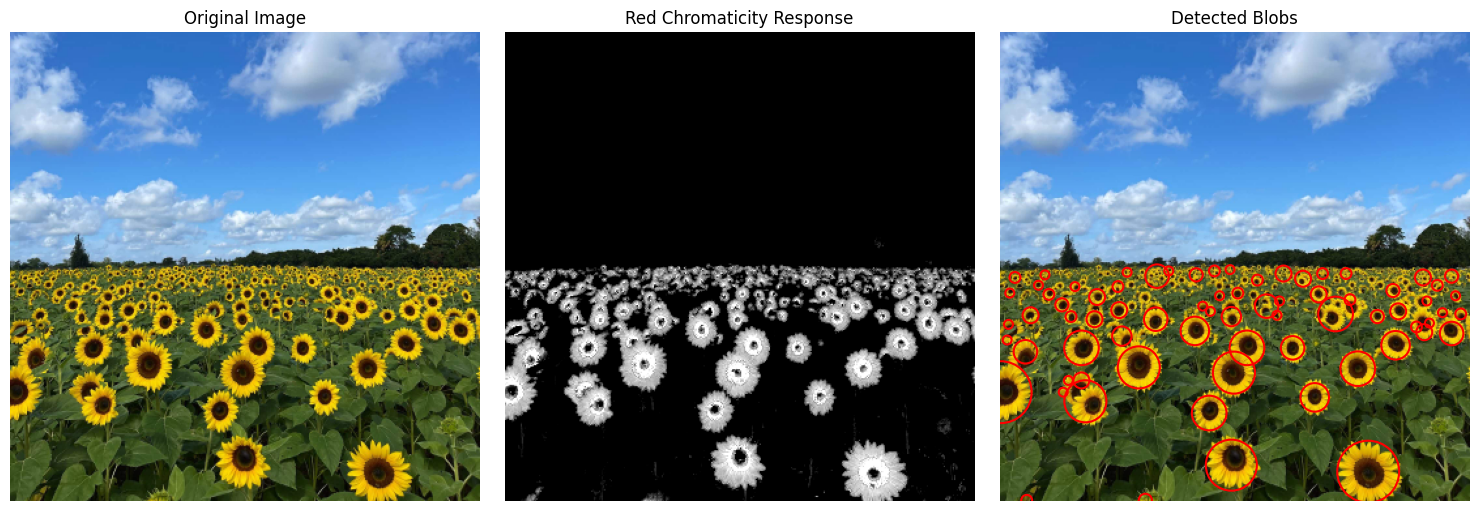

Sigma range: 2.00-30.00 (15 scales)
Radius range: 2.8-42.4 pixels
Total detected blobs: 73

Largest circles:
Center=(282, 337), sigma=16.79, radius=23.7 px
Center=(0, 276), sigma=16.79, radius=23.7 px
Center=(177, 332), sigma=13.84, radius=19.6 px
Center=(106, 257), sigma=11.40, radius=16.1 px
Center=(65, 283), sigma=11.40, radius=16.1 px


In [2]:
image = cv.imread('images/the_berry_farms_sunflower_field.jpeg', cv.IMREAD_REDUCED_COLOR_4)
assert image is not None, "Image not found"

b, g, r = [channel.astype(np.float32) / 255.0 for channel in cv.split(image)]

# red chromaticity response
red_chromaticity = r / (r + g + b + 0.03)
red_chromaticity = np.clip((red_chromaticity - 0.38) / 0.2, 0, 1)

sigmas = np.geomspace(2, 30, 15)
threshold = 0.2

response_stack = np.stack([
    sigma**2 * cv.Laplacian(
        cv.GaussianBlur(
            red_chromaticity, (0, 0), sigma
        ),
        cv.CV_32F
    )
    for sigma in sigmas
])

response_stack = -response_stack

local_maxima = (response_stack == maximum_filter(response_stack, size=(3, 3, 3)))

threshold_value = threshold * response_stack.max()
keep = local_maxima & (response_stack > threshold_value)
keep[0] = False
keep[-1] = False

scale_idx, y_coords, x_coords = np.nonzero(keep)

blobs = [
    (
        int(x),
        int(y),
        float(sigmas[k]),
        float(response_stack[k, y, x])
    )
    for k, y, x in zip(scale_idx, y_coords, x_coords)
]

detected_blobs = []

for x, y, sigma, strength in sorted(blobs, key=lambda blob: -blob[3]):
    radius = np.sqrt(2) * sigma

    is_separate = all(
        np.hypot(x - x_prev, y - y_prev)
        >= max(radius, np.sqrt(2) * sigma_prev)
        for x_prev, y_prev, sigma_prev, _ in detected_blobs
    )

    if is_separate:
        detected_blobs.append((x, y, sigma, strength))

fig, ax = plt.subplots(1, 3, figsize=(15, 5))

ax[0].imshow(cv.cvtColor(image, cv.COLOR_BGR2RGB)); ax[0].set_title('Original Image')
ax[1].imshow(red_chromaticity, cmap='gray'); ax[1].set_title('Red Chromaticity Response')
ax[2].imshow(cv.cvtColor(image, cv.COLOR_BGR2RGB))
for x, y, sigma, _ in detected_blobs:
    radius = np.sqrt(2) * sigma
    ax[2].add_patch(
        plt.Circle(
            (x, y), radius,
            color='red', fill=False, linewidth=1.5
        )
    )
ax[2].set_title('Detected Blobs')
for a in ax:
    a.axis('off')
plt.tight_layout()
plt.show()

print(f"Sigma range: {sigmas[0]:.2f}-{sigmas[-1]:.2f} ({len(sigmas)} scales)")
print(f"Radius range: {np.sqrt(2) * sigmas[0]:.1f}-{np.sqrt(2) * sigmas[-1]:.1f} pixels")
print(f"Total detected blobs: {len(detected_blobs)}")

largest_blobs = sorted(detected_blobs, key=lambda blob: -blob[2])[:5]
print(f"\nLargest circles:")
for x, y, sigma, _ in largest_blobs:
    radius = np.sqrt(2) * sigma
    print(f"Center=({x}, {y}), sigma={sigma:.2f}, radius={radius:.1f} px"    )

#### Q2. Line and Circle Fitting

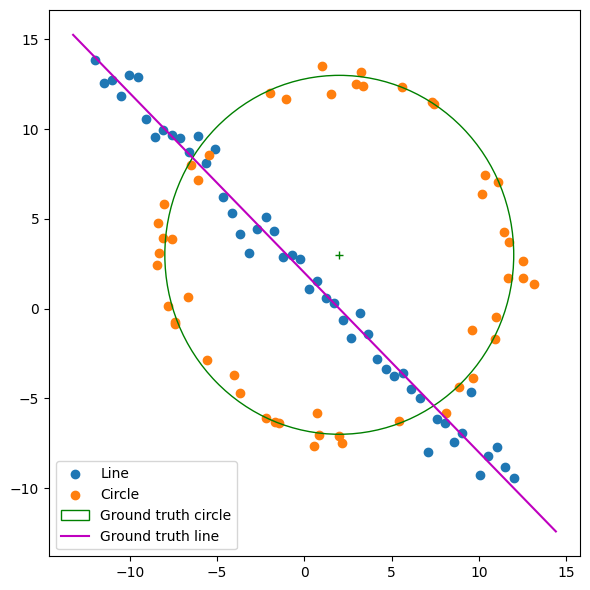

In [3]:
# np.random.seed(0)
N = 100
half_n = N//2
r = 10
x0_gt, y0_gt = 2, 3 # Center
s = r/16
t = np.random.uniform(0, 2*np.pi, half_n)
n = s*np.random.randn(half_n)
x, y = x0_gt + (r + n)*np.cos(t), y0_gt + (r + n)*np.sin(t)
X_circ = np.hstack((x.reshape(half_n ,1), y.reshape(half_n ,1)))

s = 1.
m, b = -1, 2
x = np.linspace(-12, 12, half_n)
y = m*x + b + s*np.random.randn(half_n)
X_line = np.hstack((x.reshape(half_n ,1), y.reshape(half_n ,1)))
X = np.vstack((X_circ, X_line)) # All points

fig , ax = plt.subplots(1,1, figsize =(6,6))
ax.scatter(X_line[:,0], X_line[:,1], label='Line')
ax.scatter(X_circ[:,0], X_circ[:,1] , label='Circle')
circle_gt = plt.Circle((x0_gt ,y0_gt), r, color='g', fill=False, label='Ground truth circle')
ax.add_patch(circle_gt)
ax.plot((x0_gt), (y0_gt), '+', color='g')
x_min, x_max = ax.get_xlim()
x_ = np.array([x_min, x_max])
y_ = m*x_ + b
plt.plot(x_ , y_, color='m', label='Ground truth line')
plt.legend()
plt.tight_layout()
plt.show()

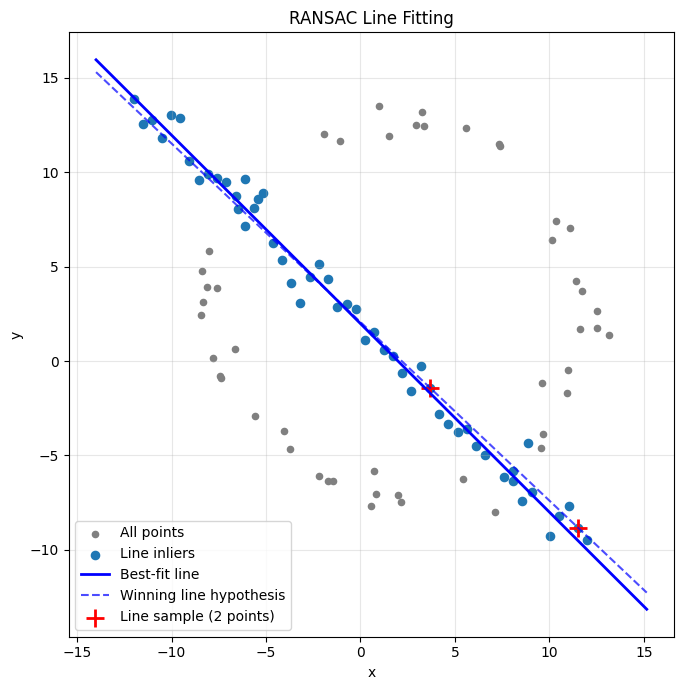

Estimated line: 0.71 * x + 0.71 * y + -1.40 = 0


In [4]:
def line_from_two_points(p1, p2):
    direction = p2 - p1

    if np.linalg.norm(direction) < 1e-10:
        return None

    normal = np.array([-direction[1], direction[0]])
    normal = normal / np.linalg.norm(normal)

    a, b = normal
    d = -np.dot(normal, p1)

    return np.array([a, b, d])

def line_distances(points, line):
    a, b, d = line
    return np.abs(a * points[:, 0] + b * points[:, 1] + d)

def fit_line_tls(points):
    centroid = np.mean(points, axis=0)
    centered = points - centroid

    _, _, Vt = np.linalg.svd(centered, full_matrices=False)

    normal = Vt[-1]
    normal = normal / np.linalg.norm(normal)

    d = -np.dot(normal, centroid)

    return np.array([normal[0], normal[1], d])

def ransac_line(points, threshold=1.5, iterations=5000, min_inliers=35):

    best_line = None
    best_inliers = None
    best_count = 0
    best_sample = None

    for _ in range(iterations):
        sample_indices = np.random.choice(len(points), 2, replace=False)
        sample = points[sample_indices]

        candidate = line_from_two_points(sample[0], sample[1])

        if candidate is None:
            continue

        distances = line_distances(points, candidate)
        inliers = distances < threshold
        count = np.sum(inliers)

        if count > best_count:
            best_count = count
            best_line = candidate
            best_inliers = inliers
            best_sample = sample.copy()

    if best_count < min_inliers:
        raise RuntimeError("Insufficient line consensus.")

    refined_line = fit_line_tls(points[best_inliers])

    return refined_line, best_inliers, best_line, best_sample

line_fit, line_inliers, line_sample_model, line_sample = (ransac_line(X))

fig, ax = plt.subplots(figsize=(7, 7))

ax.scatter(X[:, 0], X[:, 1], s=20, color="gray", label="All points")
ax.scatter(X[line_inliers, 0], X[line_inliers, 1], s=35, color="tab:blue", label="Line inliers")

a, b, d = line_fit
x_plot = np.linspace(X[:, 0].min() - 2, X[:, 0].max() + 2, 500)

if abs(b) > 1e-10:
    y_plot = -(a * x_plot + d) / b
    ax.plot(x_plot, y_plot, "b-", linewidth=2, label="Best-fit line")

a_s, b_s, d_s = line_sample_model
if abs(b_s) > 1e-10:
    y_sample = -(a_s * x_plot + d_s) / b_s
    ax.plot(x_plot, y_sample, "b--", alpha=0.7, label="Winning line hypothesis")

ax.scatter(
    line_sample[:, 0], line_sample[:, 1],
    s=150, marker="+", linewidths=2,
    color="red", label="Line sample (2 points)"
)

ax.set_aspect("equal", adjustable="box")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("RANSAC Line Fitting")
ax.grid(True, alpha=0.3)
ax.legend(loc="best")
plt.tight_layout()
plt.show()

print(f"Estimated line: {a:.2f} * x + {b:.2f} * y + {d:.2f} = 0")

In [5]:
X_remaining = X[~line_inliers]
print("Line consensus:", np.sum(line_inliers))
print("Remaining points:", len(X_remaining))

Line consensus: 53
Remaining points: 47


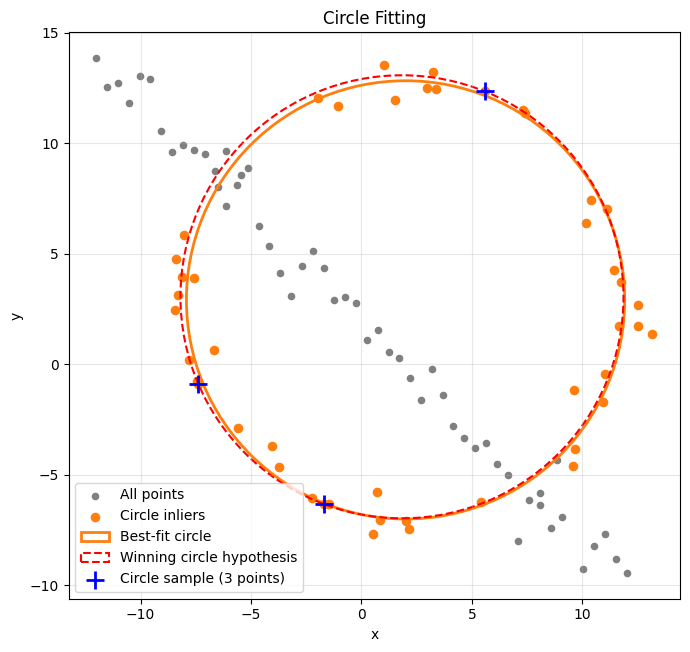

Circle consensus: 46
Estimated circle: (x-1.99)^2 + (y-2.91)^2 = 9.92^2


In [6]:
def circle_from_three_points(points):
    p1, p2, p3 = points
    A = 2 * np.array([p2 - p1, p3 - p1])
    rhs = np.array([np.dot(p2, p2) - np.dot(p1, p1), np.dot(p3, p3) - np.dot(p1, p1)])
    if abs(np.linalg.det(A)) < 1e-8:
        return None
    center = np.linalg.solve(A, rhs)
    radius = np.linalg.norm(p1 - center)
    return np.array([center[0], center[1], radius])

def circle_distances(points, circle):
    cx, cy, radius = circle
    radial_distances = np.sqrt((points[:, 0] - cx)**2 + (points[:, 1] - cy)**2)
    return np.abs(radial_distances - radius)


def ransac_circle(points, threshold=1.5, iterations=10000, min_inliers=35):

    best_circle = None
    best_inliers = None
    best_count = 0
    best_sample = None

    for _ in range(iterations):
        sample_indices = np.random.choice(len(points), 3, replace=False)
        sample = points[sample_indices]

        candidate = circle_from_three_points(sample)

        if candidate is None:
            continue

        distances = circle_distances(points, candidate)
        inliers = distances < threshold
        count = np.sum(inliers)

        if count > best_count:
            best_count = count
            best_circle = candidate
            best_inliers = inliers
            best_sample = sample.copy()

    if best_count < min_inliers:
        raise RuntimeError("Insufficient circle consensus.")

    return best_circle, best_inliers, best_sample

circle_sample_model, circle_inliers, circle_sample = (ransac_circle(X_remaining))

circle_points = X_remaining[circle_inliers]

def circle_objective(params, points):
    cx, cy, radius = params
    distances = np.sqrt((points[:, 0] - cx)**2 + (points[:, 1] - cy)**2)
    residuals = distances - radius
    return np.sum(residuals**2)

optimization = minimize(
    circle_objective,
    circle_sample_model,
    args=(circle_points,),
    method="Nelder-Mead",
    bounds=[(None, None), (None, None), (1e-6, None)]
)

circle_fit = optimization.x

fig, ax = plt.subplots(figsize=(7, 7))

ax.scatter(X[:, 0], X[:, 1], s=20, color="gray", label="All points")
ax.scatter(circle_points[:, 0], circle_points[:, 1], s=35, color="tab:orange", label="Circle inliers")

cx, cy, radius = circle_fit
best_circle = plt.Circle(
    (cx, cy), radius, fill=False,
    color="tab:orange", linewidth=2,
    label="Best-fit circle"
)
ax.add_patch(best_circle)

cx_s, cy_s, r_s = circle_sample_model
sample_circle = plt.Circle(
    (cx_s, cy_s), r_s, fill=False,
    color="red", linestyle="--", linewidth=1.5,
    label="Winning circle hypothesis"
)
ax.add_patch(sample_circle)

ax.scatter(
    circle_sample[:, 0], circle_sample[:, 1],
    s=150, marker="+", linewidths=2,
    color="blue", label="Circle sample (3 points)"
)

ax.set_aspect("equal", adjustable="box")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("Circle Fitting")
ax.grid(True, alpha=0.3)
ax.legend(loc="best")
plt.tight_layout()
plt.show()

print("Circle consensus:", np.sum(circle_inliers))
print(f"Estimated circle: (x-{cx:.2f})^2 + (y-{cy:.2f})^2 = {radius:.2f}^2")

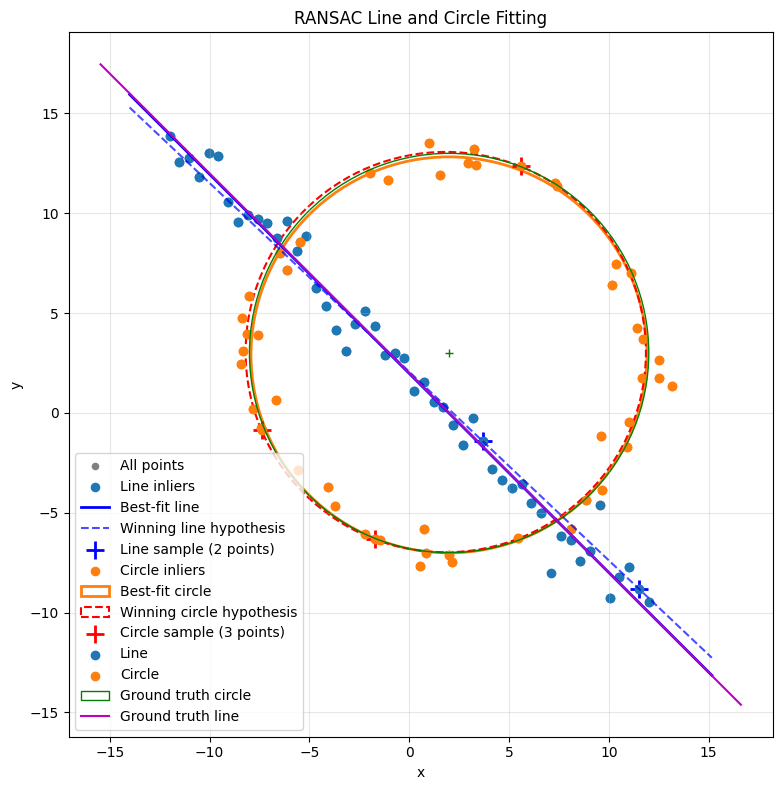

In [7]:
fig, ax = plt.subplots(figsize=(10, 8))

ax.scatter(X[:, 0], X[:, 1], s=20, color="gray", label="All points")

ax.scatter(X[line_inliers, 0], X[line_inliers, 1],s=35, color="tab:blue", label="Line inliers")

a, b, d = line_fit
x_plot = np.linspace(X[:, 0].min() - 2, X[:, 0].max() + 2, 500)

if abs(b) > 1e-10:
    y_plot = -(a * x_plot + d) / b
    ax.plot(x_plot, y_plot,"b-", linewidth=2, label="Best-fit line")

a_s, b_s, d_s = line_sample_model

if abs(b_s) > 1e-10:
    y_sample = -(a_s * x_plot + d_s) / b_s
    ax.plot(x_plot, y_sample,
        "b--", alpha=0.7, label="Winning line hypothesis")

ax.scatter(
    line_sample[:, 0], line_sample[:, 1],
    s=150, marker="+", linewidths=2,
    color="blue", label="Line sample (2 points)"
)

ax.scatter(
    circle_points[:, 0], circle_points[:, 1],
    s=35, color="tab:orange", label="Circle inliers"
)

cx, cy, radius = circle_fit
best_circle = plt.Circle(
    (cx, cy), radius, fill=False,
    color="tab:orange", linewidth=2,
    label="Best-fit circle"
)
ax.add_patch(best_circle)

cx_s, cy_s, r_s = circle_sample_model
sample_circle = plt.Circle(
    (cx_s, cy_s), r_s, fill=False,
    color="red", linestyle="--", linewidth=1.5,
    label="Winning circle hypothesis"
)
ax.add_patch(sample_circle)

ax.scatter(
    circle_sample[:, 0], circle_sample[:, 1],
    s=150, marker="+", linewidths=2,
    color="red", label="Circle sample (3 points)"
)

ax.scatter(X_line[:,0], X_line[:,1], label='Line')
ax.scatter(X_circ[:,0], X_circ[:,1] , label='Circle')
circle_gt = plt.Circle((x0_gt ,y0_gt), r, color='g', fill=False, label='Ground truth circle')
ax.add_patch(circle_gt)
ax.plot((x0_gt), (y0_gt), '+', color='g')
x_min, x_max = ax.get_xlim()
x_ = np.array([x_min, x_max])
y_ = -x_ + 2
plt.plot(x_ , y_, color='m', label='Ground truth line')

ax.set_aspect("equal", adjustable="box")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("RANSAC Line and Circle Fitting")
ax.grid(True, alpha=0.3)
ax.legend(loc="best")
plt.tight_layout()
plt.show()

What happens if we fit the circle first?

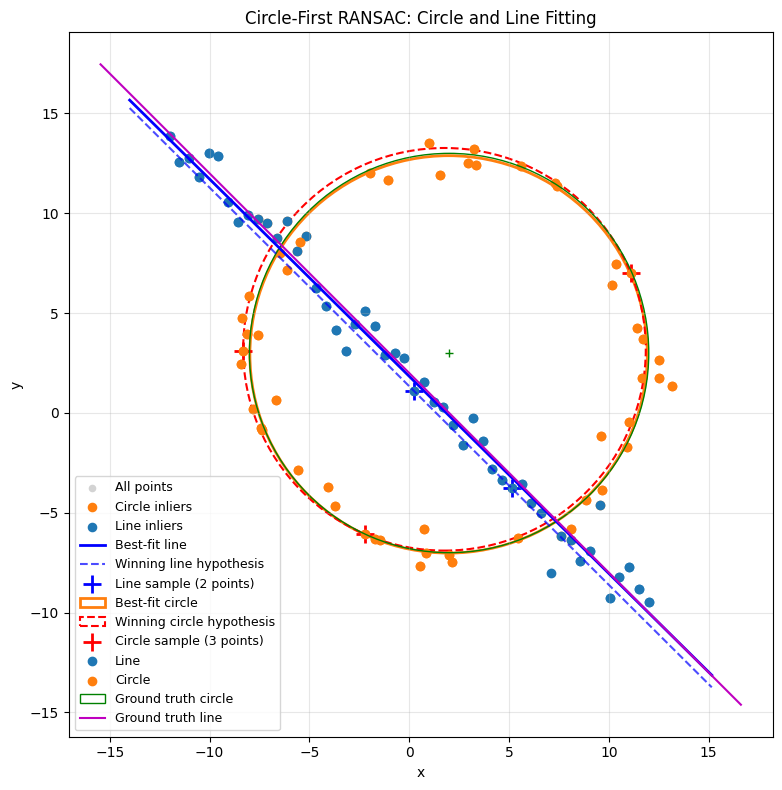

In [8]:
circle_sample_model, circle_inliers, circle_sample = ransac_circle(X)

circle_points = X[circle_inliers]
X_remaining = X[~circle_inliers]

optimization = minimize(
    circle_objective,
    circle_sample_model,
    args=(circle_points,),
    method="Nelder-Mead",
    bounds=[(None, None), (None, None), (1e-6, None)]
)

circle_fit = optimization.x

line_fit, line_inliers, line_sample_model, line_sample = ransac_line(X_remaining)

line_points = X_remaining[line_inliers]

fig, ax = plt.subplots(figsize=(10, 8))

ax.scatter(X[:, 0], X[:, 1], s=20, color="lightgray", label="All points")

ax.scatter(circle_points[:, 0], circle_points[:, 1], s=35, color="tab:orange", label="Circle inliers")

ax.scatter(line_points[:, 0], line_points[:, 1], s=35, color="tab:blue", label="Line inliers")

a, b, d = line_fit

x_plot = np.linspace(X[:, 0].min() - 2, X[:, 0].max() + 2, 500)

if abs(b) > 1e-10:
    y_plot = -(a * x_plot + d) / b
    ax.plot(x_plot, y_plot, color="blue", linewidth=2, label="Best-fit line")
else:
    if abs(a) > 1e-10:
        ax.axvline(-d / a, color="blue", linewidth=2, label="Best-fit line")

a_s, b_s, d_s = line_sample_model

if abs(b_s) > 1e-10:
    y_sample = -(a_s * x_plot + d_s) / b_s
    ax.plot(
        x_plot, y_sample,
        color="blue", linestyle="--", alpha=0.7,
        label="Winning line hypothesis", zorder=2
    )
else:
    if abs(a_s) > 1e-10:
        ax.axvline(
            -d_s / a_s, color="blue", linestyle="--",
            alpha=0.7, label="Winning line hypothesis",
        )

ax.scatter(
    line_sample[:, 0], line_sample[:, 1],
    s=150, marker="+", linewidths=2,
    color="blue", label="Line sample (2 points)",
)

cx, cy, radius = circle_fit

best_circle = plt.Circle(
    (cx, cy), radius,
    fill=False, color="tab:orange",
    linewidth=2, label="Best-fit circle",
)
ax.add_patch(best_circle)

cx_s, cy_s, r_s = circle_sample_model

sample_circle = plt.Circle(
    (cx_s, cy_s), r_s,
    fill=False, color="red",
    linestyle="--", linewidth=1.5,
    label="Winning circle hypothesis",
)
ax.add_patch(sample_circle)

ax.scatter(
    circle_sample[:, 0], circle_sample[:, 1],
    s=150, marker="+", linewidths=2,
    color="red", label="Circle sample (3 points)",
)

ax.scatter(X_line[:,0], X_line[:,1], label='Line')
ax.scatter(X_circ[:,0], X_circ[:,1] , label='Circle')
circle_gt = plt.Circle((x0_gt ,y0_gt), r, color='g', fill=False, label='Ground truth circle')
ax.add_patch(circle_gt)
ax.plot((x0_gt), (y0_gt), '+', color='g')
x_min, x_max = ax.get_xlim()
x_ = np.array([x_min, x_max])
y_ = -x_ + 2
plt.plot(x_ , y_, color='m', label='Ground truth line')

ax.set_aspect("equal", adjustable="box")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("Circle-First RANSAC: Circle and Line Fitting")
ax.grid(True, alpha=0.3)
ax.legend(loc="best", fontsize=9)

plt.tight_layout()
plt.show()

As seen above, the line appears to fit better when it is fitted first, while the circle fit changes relatively little. This suggests that circle-first fitting may remove some genuine line points, whereas the circle estimation is less affected by the order of fitting. Overall, the order of fitting can influence the results because RANSAC relies on distance thresholds to classify inliers, and points from different models may overlap.

#### Q3. Image Superimposing

In [13]:
def select_four_points(image):
    points = []
    display = image.copy()
    window = "Select 4 corners: TL, TR, BR, BL"

    cv.namedWindow(window)

    def click_event(event, x, y, flags, param):
        if event == cv.EVENT_LBUTTONDOWN and len(points) < 4:
            points.append([x, y])
            cv.circle(display, (x, y), 2, (0, 0, 255), -1)
            cv.imshow(window, display)

    cv.setMouseCallback(window, click_event)
    cv.imshow(window, display)

    while len(points) < 4:
        cv.waitKey(20)

    cv.destroyWindow(window)
    return np.float32(points)

def composite_overlay(background_path, overlay_path, alpha):
    background = cv.imread(background_path)
    overlay = cv.imread(overlay_path)

    h, w = overlay.shape[:2]
    H = cv.getPerspectiveTransform(
        np.float32([[0, 0], [w-1, 0], [w-1, h-1], [0, h-1]]),
        select_four_points(background)
    )

    warped = cv.warpPerspective(overlay, H, (background.shape[1], background.shape[0]))

    mask = cv.warpPerspective(
        np.ones((h, w), dtype=np.uint8) * 255,
        H, (background.shape[1], background.shape[0])
    )

    blended = cv.addWeighted(background, 1-alpha, warped, alpha, 0)
    result = np.where(mask[:, :, None] > 0, blended, background)

    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    for ax, img, title in zip(
        axes,
        [background, overlay, result],
        ["Original Image", "Overlay", "Final Composite Image"]
    ):
        ax.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
        ax.set_title(title)
        ax.axis("off")
    plt.tight_layout()
    plt.show()

    return result, H

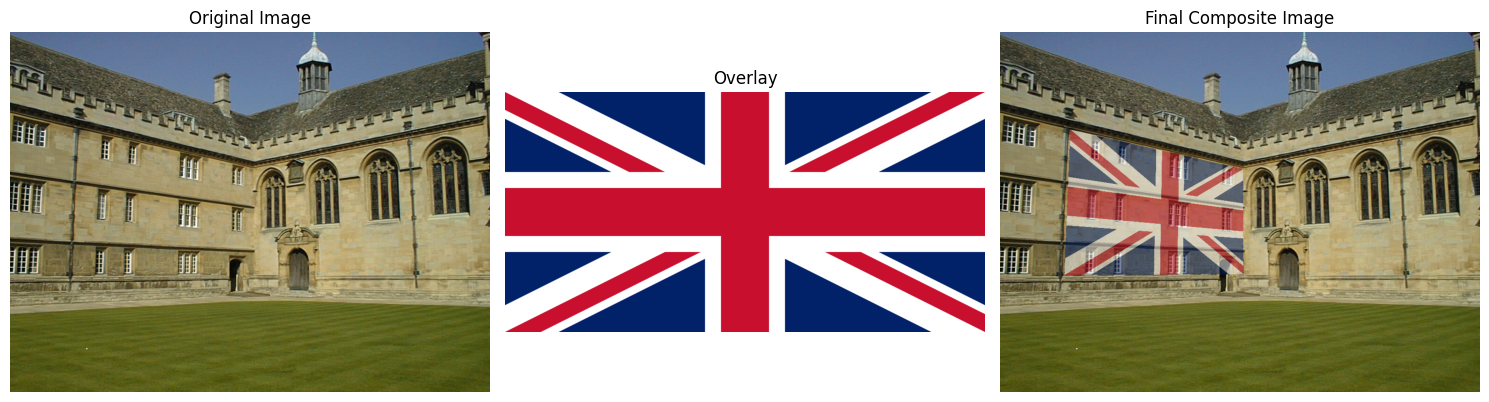

In [16]:
result, H = composite_overlay("images/wadham.jpg", "images/flag.png", 0.5)

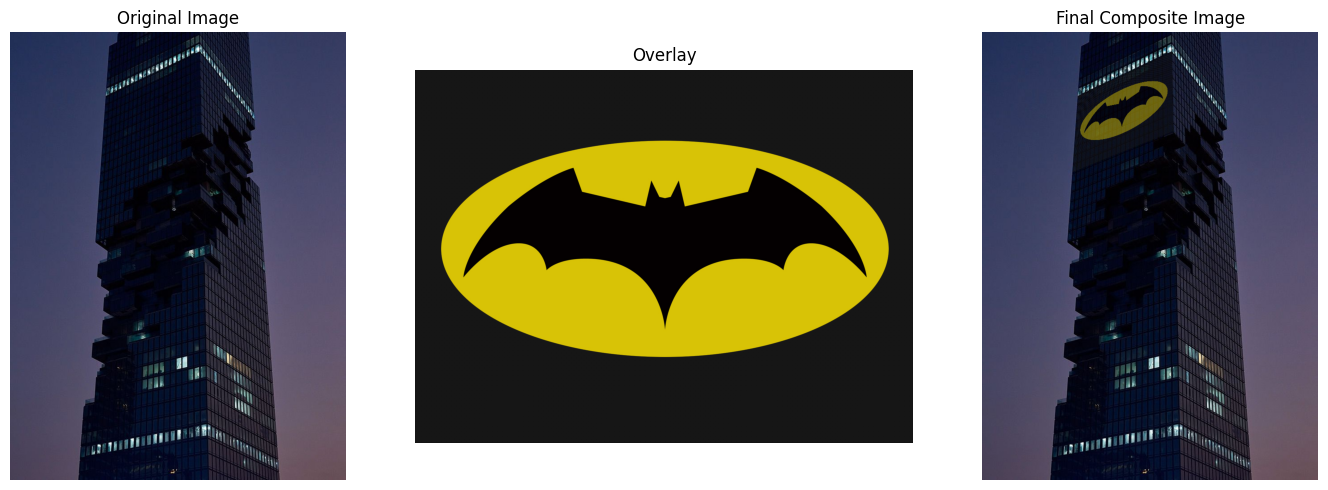

In [17]:
result, H = composite_overlay("images/skyscraper.jpg", "images/batman_logo.jpg", 0.5)

These examples were chosen because structures like building facades provide approximately planar surfaces on which graphics can be realistically superimposed. The results demonstrate how a homography can transfer an image onto a surface viewed from a different perspective.

#### Q4. Image Alignment

Reference keypoints: 14271
AECC2: 4607 matches, 3951 RANSAC inliers


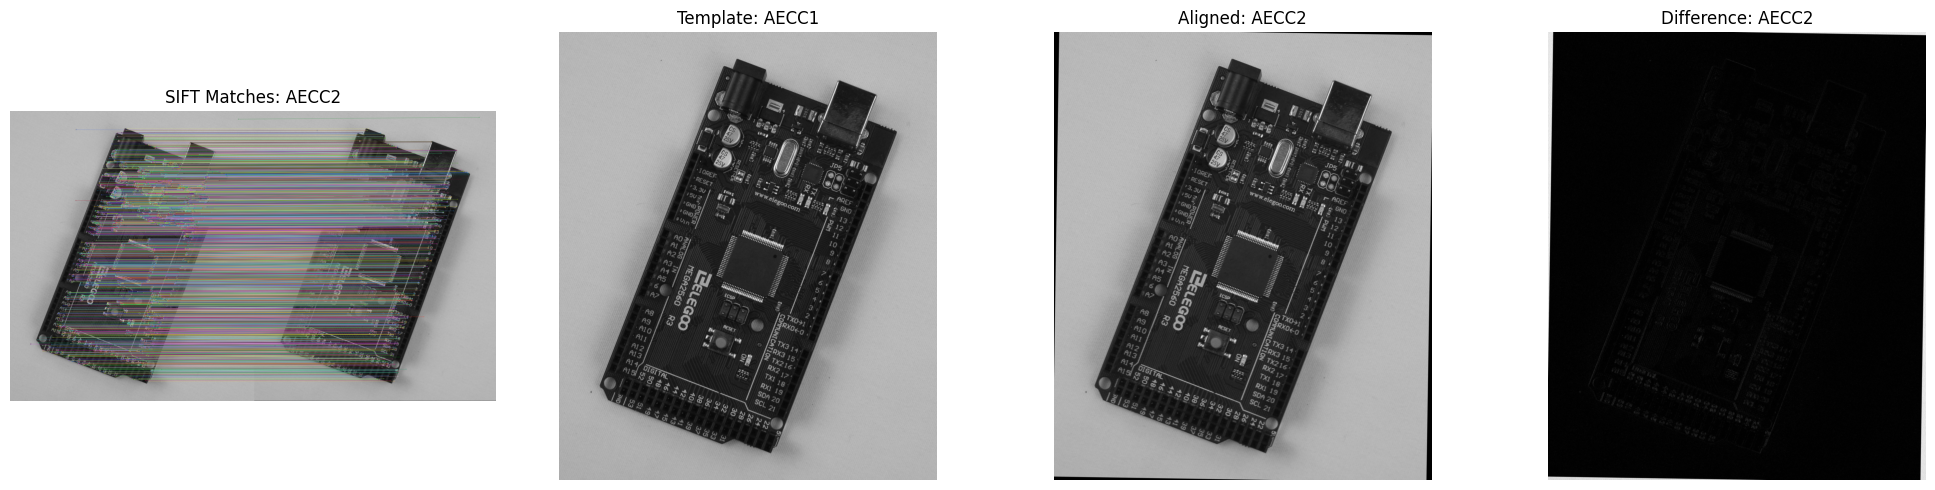

AECC3: 5649 matches, 4995 RANSAC inliers


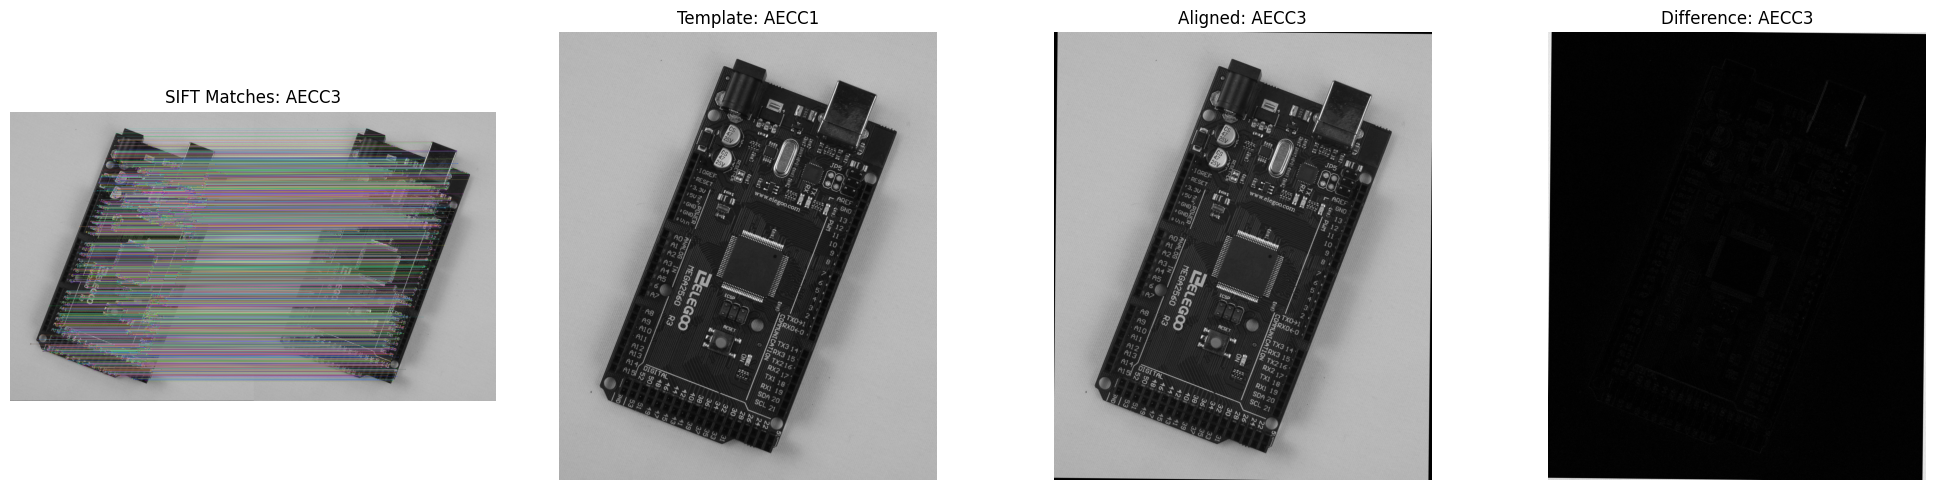

AECC4: 4006 matches, 3421 RANSAC inliers


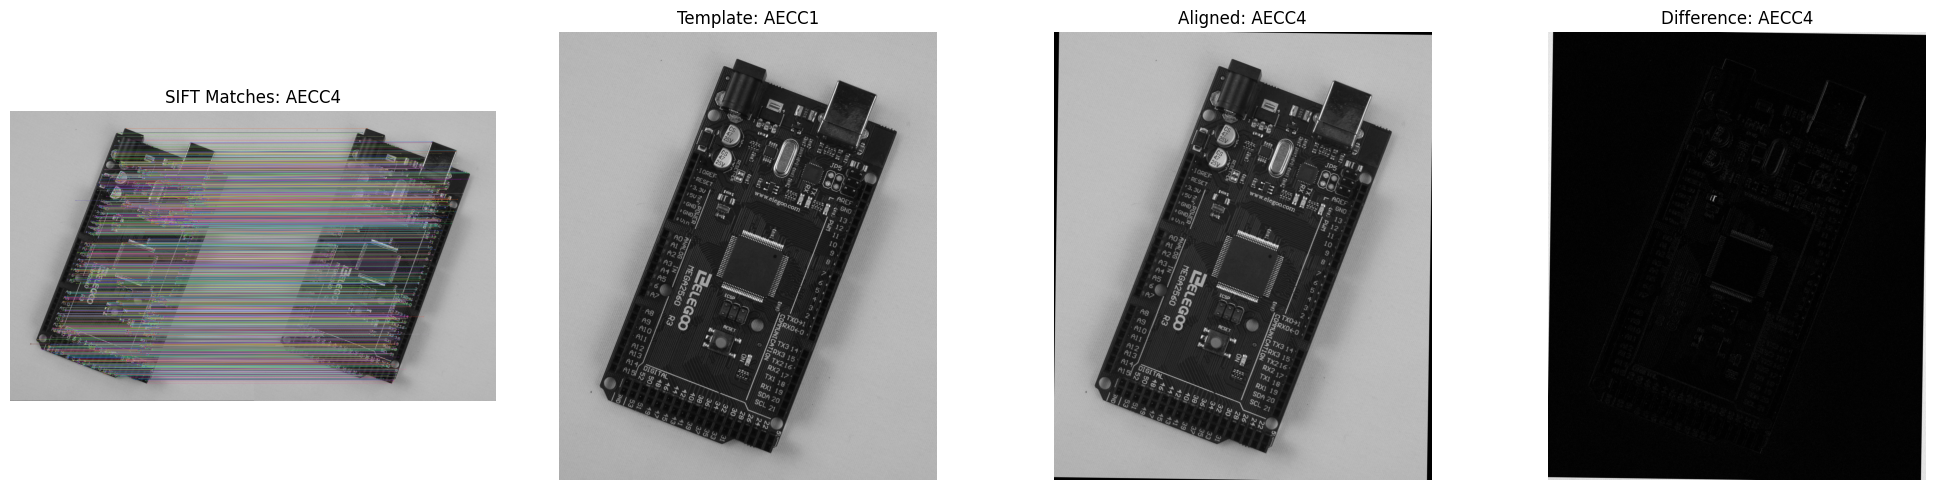

AAAA1: 397 matches, 7 RANSAC inliers


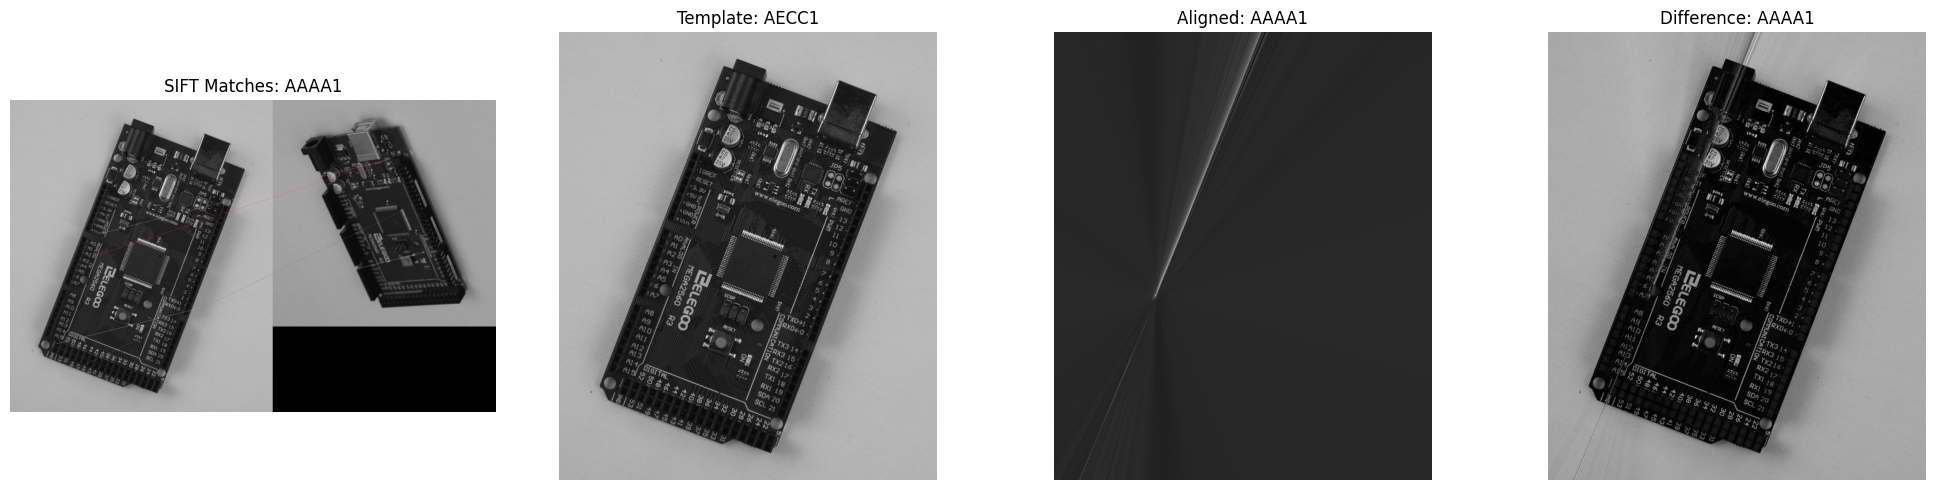

ADAD1: 656 matches, 226 RANSAC inliers


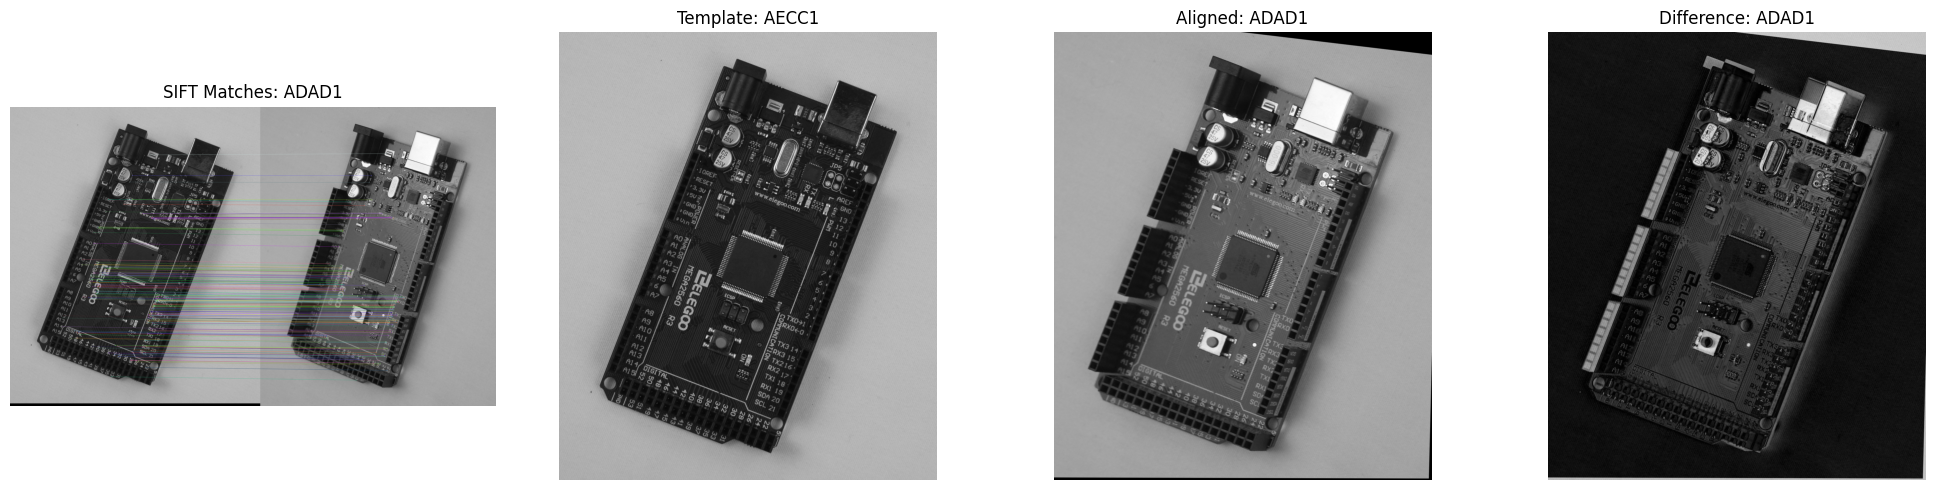

In [24]:
reference = cv.imread('images/pcbs/AECC1.jpg', cv.IMREAD_GRAYSCALE)
pcb_images = [
    ('AECC2', cv.imread('images/pcbs/AECC2.jpg', cv.IMREAD_GRAYSCALE)),
    ('AECC3', cv.imread('images/pcbs/AECC3.jpg', cv.IMREAD_GRAYSCALE)),
    ('AECC4', cv.imread('images/pcbs/AECC4.jpg', cv.IMREAD_GRAYSCALE)),
    ('AAAA1', cv.imread('images/pcbs/AAAA1.jpg', cv.IMREAD_GRAYSCALE)),
    ('ADAD1', cv.imread('images/pcbs/ADAD1.jpg', cv.IMREAD_GRAYSCALE))
]

if reference is None or any(img is None for _, img in pcb_images):
    raise FileNotFoundError("Check the PCB image paths.")

# Detect SIFT features
sift = cv.SIFT_create()
ref_kp, ref_des = sift.detectAndCompute(reference, None)
matcher = cv.BFMatcher()
print("Reference keypoints:", len(ref_kp))

def process_pcb(name, image):
    kp, des = sift.detectAndCompute(image, None)
    pairs = matcher.knnMatch(ref_des, des, k=2)
    matches = [m for m, n in pairs if m.distance < 0.75 * n.distance]
    if len(matches) < 4:
        print(f"{name}: Not enough matches for alignment.")
        return
    ref_points = np.float32([ref_kp[m.queryIdx].pt for m in matches]).reshape(-1, 1, 2)
    pcb_points = np.float32([kp[m.trainIdx].pt for m in matches]).reshape(-1, 1, 2)
    H, inliers = cv.findHomography(pcb_points, ref_points, cv.RANSAC, 5.0)
    if H is None:
        print(f"{name}: Homography estimation failed.")
        return
    print(f"{name}: {len(matches)} matches, {int(inliers.sum())} RANSAC inliers")

    match_view = cv.drawMatches(
        reference, ref_kp, image, kp, matches, None,
        matchesMask=inliers.ravel().tolist(),
        flags=cv.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
    )
    height, width = reference.shape
    aligned = cv.warpPerspective(image, H, (width, height))
    difference = cv.absdiff(reference, aligned)

    fig, ax = plt.subplots(1, 4, figsize=(20, 5))

    images = [
        (match_view, f'SIFT Matches: {name}'),
        (reference, 'Template: AECC1'),
        (aligned, f'Aligned: {name}'),
        (difference, f'Difference: {name}'),
    ]

    for a, (img, title) in zip(ax, images):
        a.imshow(img, cmap='gray')
        a.set_title(title)
        a.axis('off')
    plt.tight_layout()
    plt.show()

    return aligned, difference

for name, image in pcb_images:
    process_pcb(name, image)

The USB port, capacitors, and reset button show relatively high differences because these components have different positions, orientations, and physical appearances in the images. Differences in lighting, shadows, and reflections from metallic surfaces also contribute to the observed pixel differences. Furthermore, the homography aligns the images globally but may not completely correct local misalignments or perspective variations around individual components.